<a href="https://colab.research.google.com/github/Viswandh-Crypto/Face_Recognition-insightface-chromadb/blob/main/Face_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
print("Python version:", sys.version)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
%pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93


In [ ]:
%pip install opencv-python-headless==4.10.0.84

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 14.2 MB/s eta 0:00:00


In [ ]:
import cv2

print("OpenCV version:", cv2.__version__)
print("OpenCV location:", cv2.__file__)
print("CascadeClassifier available:",
      hasattr(cv2, "CascadeClassifier"))

OpenCV version: 4.10.0
OpenCV location: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
CascadeClassifier available: True


In [ ]:
import cv2
import os

haar_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

assert not haar_cascade.empty(), "Failed to load Haar Cascade!"

print("Face detector loaded successfully!")

Face detector loaded successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving avengers_infinity_war.png to avengers_infinity_war.png


Image shape: (2250, 3000, 3)


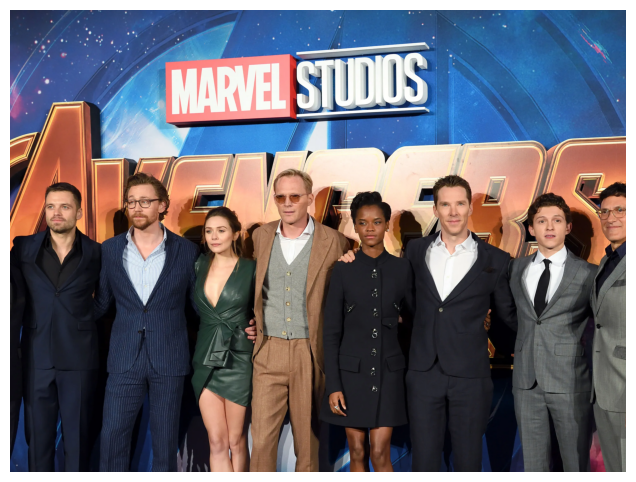

In [ ]:
import cv2
import matplotlib.pyplot as plt

image_path = next(iter(uploaded.keys()))
img = cv2.imread(image_path)

if img is None:
    raise ValueError("Could not load the uploaded image.")

print("Image shape:", img.shape)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
# Convert the image to grayscale
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Improve contrast
gray_img = cv2.equalizeHist(gray_img)

faces = haar_cascade.detectMultiScale(
    gray_img,
    scaleFactor=1.1,
    minNeighbors=7,
    minSize=(100, 100),
    flags=cv2.CASCADE_SCALE_IMAGE
)

print(f"Found {len(faces)} face(s)")

Found 7 face(s)


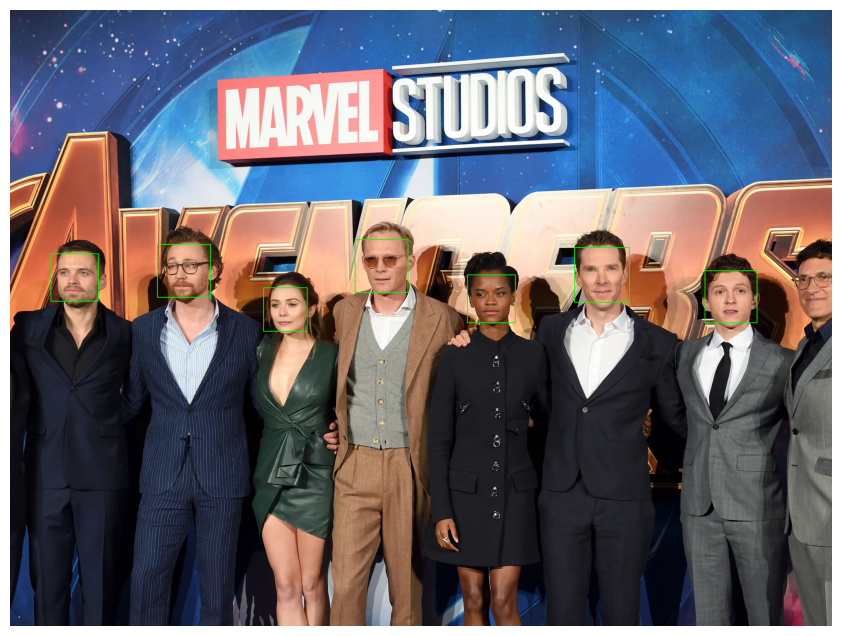

Detected regions: 7


In [ ]:
import matplotlib.pyplot as plt

img_display = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        img_display,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(12, 8))
plt.imshow(img_display)
plt.axis("off")
plt.show()

print("Detected regions:", len(faces))

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

os.makedirs("stored-faces", exist_ok=True)

for i, (x, y, w, h) in enumerate(faces):
    cropped_face = img[y:y+h, x:x+w]

    cv2.imwrite(
        f"stored-faces/face_{i}.jpg",
        cropped_face
    )

print(f"Saved {len(faces)} cropped faces.")

Saved 7 cropped faces.


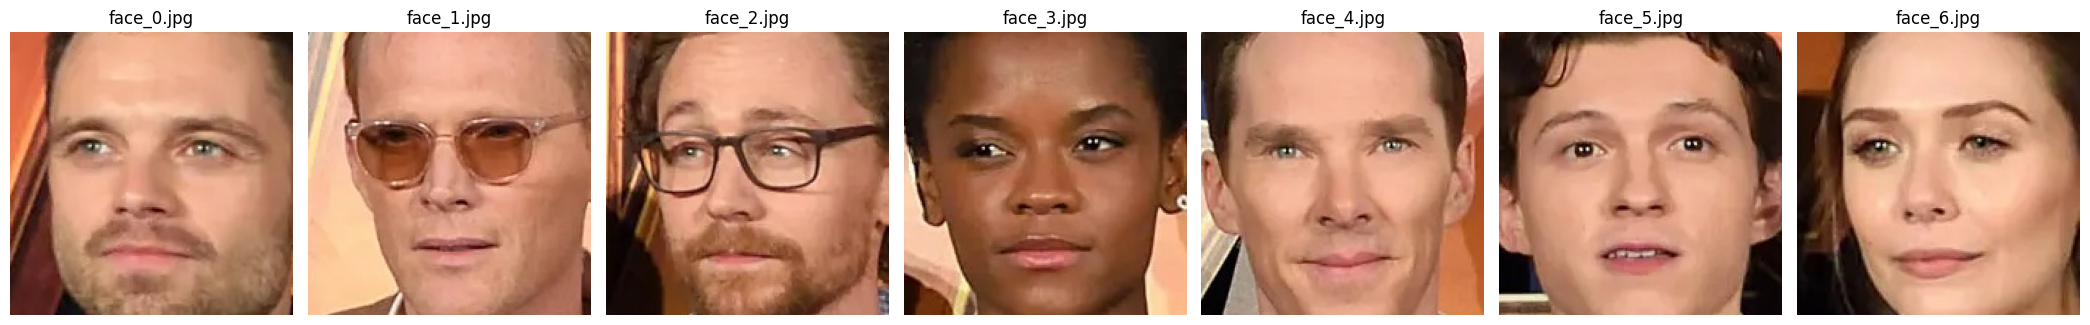

In [ ]:
from glob import glob

face_files = sorted(glob("stored-faces/*.jpg"))

fig, axes = plt.subplots(
    1, len(face_files),
    figsize=(3 * len(face_files), 4)
)

if len(face_files) == 1:
    axes = [axes]

for ax, path in zip(axes, face_files):
    face = cv2.imread(path)
    ax.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(path))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import os
from glob import glob

face_files = sorted(glob("stored-faces/face_*.jpg"))

print("Total cropped faces:", len(face_files))

for path in face_files:
    face = cv2.imread(path)
    h, w = face.shape[:2]
    print(os.path.basename(path), "->", w, "x", h)

Total cropped faces: 7
face_0.jpg -> 173 x 173
face_1.jpg -> 193 x 193
face_2.jpg -> 193 x 193
face_3.jpg -> 175 x 175
face_4.jpg -> 200 x 200
face_5.jpg -> 190 x 190
face_6.jpg -> 159 x 159


In [ ]:
%pip install insightface onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 7.8 MB/s eta 0:00:00


In [ ]:
import cv2
import numpy as np
from insightface.app import FaceAnalysis

app = FaceAnalysis(
    name="buffalo_l",
    providers=["CPUExecutionProvider"]
)

app.prepare(
    ctx_id=-1,
    det_size=(640, 640)
)

print("InsightFace model loaded successfully!")

download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:07<00:00, 37727.91KB/s]


InsightFace model loaded successfully!


In [ ]:
import os
from glob import glob

face_files = sorted(glob("stored-faces/face_*.jpg"))
face_embeddings = []

for path in face_files:
    image = cv2.imread(path)

    if image is None:
        print("Could not read:", path)
        continue

    detected_faces = app.get(image)

    if len(detected_faces) == 0:
        print("No face detected in:", os.path.basename(path))
        continue

    # Use the largest detected face
    face = max(
        detected_faces,
        key=lambda f: (
            (f.bbox[2] - f.bbox[0]) *
            (f.bbox[3] - f.bbox[1])
        )
    )

    embedding = face.normed_embedding

    face_embeddings.append({
        "id": os.path.splitext(os.path.basename(path))[0],
        "embedding": embedding.tolist()
    })

print("Embeddings generated:", len(face_embeddings))

if face_embeddings:
    print(
        "Embedding dimensions:",
        len(face_embeddings[0]["embedding"])
    )

No face detected in: face_0.jpg
No face detected in: face_1.jpg
No face detected in: face_2.jpg
No face detected in: face_3.jpg
No face detected in: face_4.jpg
No face detected in: face_5.jpg
No face detected in: face_6.jpg
Embeddings generated: 0


Image shape: (173, 173, 3)


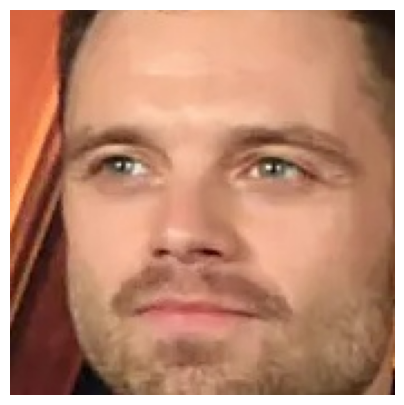

In [ ]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("stored-faces/face_0.jpg")

print("Image shape:", image.shape)

plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
app.prepare(
    ctx_id=-1,
    det_size=(320, 320),
    det_thresh=0.2
)

print("InsightFace detector updated!")

InsightFace detector updated!


In [ ]:
image = cv2.imread("stored-faces/face_0.jpg")
detected_faces = app.get(image)

print("Faces detected:", len(detected_faces))

Faces detected: 1


In [ ]:
import cv2
import os
import numpy as np

face_embeddings = []
failed_faces = []

for path in face_files:
    image = cv2.imread(path)

    if image is None:
        failed_faces.append(os.path.basename(path))
        continue

    detected_faces = app.get(image)

    if not detected_faces:
        print("No face detected:", os.path.basename(path))
        failed_faces.append(os.path.basename(path))
        continue

    # Select the largest detected face
    face = max(
        detected_faces,
        key=lambda f: (
            (f.bbox[2] - f.bbox[0]) *
            (f.bbox[3] - f.bbox[1])
        )
    )

    embedding = face.normed_embedding

    face_embeddings.append({
        "id": os.path.splitext(os.path.basename(path))[0],
        "embedding": embedding.astype(float).tolist()
    })

print("\nEmbeddings generated:", len(face_embeddings))
print("Failed crops:", len(failed_faces))

if face_embeddings:
    print(
        "Embedding dimensions:",
        len(face_embeddings[0]["embedding"])
    )


Embeddings generated: 7
Failed crops: 0
Embedding dimensions: 512


In [ ]:
%pip install chromadb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 51.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 972.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 9.7 MB/s eta 0:00:00
  Attempting uninstall: urllib3
    Found existin

In [ ]:

import os
import cv2
import chromadb
from glob import glob

# 1. Recover embeddings if they are missing
if "face_embeddings" not in globals() or not face_embeddings:

    if "app" not in globals():
        raise RuntimeError(
            "InsightFace model is not loaded. "
            "Run the model initialization cell first."
        )

    face_files = sorted(glob("stored-faces/face_*.jpg"))
    face_embeddings = []

    for path in face_files:
        image = cv2.imread(path)

        if image is None:
            continue

        detections = app.get(image)

        if not detections:
            print("Skipped:", os.path.basename(path))
            continue

        face = max(
            detections,
            key=lambda f: (
                (f.bbox[2] - f.bbox[0]) *
                (f.bbox[3] - f.bbox[1])
            )
        )

        face_embeddings.append({
            "id": os.path.splitext(os.path.basename(path))[0],
            "embedding": face.normed_embedding.astype(float).tolist()
        })

# 2. Connect to ChromaDB
client = chromadb.PersistentClient(path="/content/chroma_db")

collection = client.get_or_create_collection(
    name="face_embeddings",
    metadata={"hnsw:space": "cosine"}
)

# 3. Store the vectors
if not face_embeddings:
    raise RuntimeError("No embeddings available to store.")

collection.upsert(
    ids=[item["id"] for item in face_embeddings],
    embeddings=[item["embedding"] for item in face_embeddings],
    metadatas=[
        {"source": item["id"] + ".jpg"}
        for item in face_embeddings
    ]
)

print("Embeddings generated:", len(face_embeddings))
print("Embeddings stored:", collection.count())


RuntimeError: InsightFace model is not loaded. Run the model initialization cell first.

In [ ]:
import chromadb

client = chromadb.PersistentClient(
    path="/content/chroma_db"
)

collection = client.get_or_create_collection(
    name="face_embeddings",
    metadata={"hnsw:space": "cosine"}
)

print("ChromaDB initialized:", collection.name)

ChromaDB initialized: face_embeddings


In [ ]:

from insightface.app import FaceAnalysis

app = FaceAnalysis(
    name="buffalo_l",
    providers=["CPUExecutionProvider"]
)

app.prepare(
    ctx_id=-1,
    det_size=(320, 320),
    det_thresh=0.2
)

print("InsightFace model loaded successfully!")


InsightFace model loaded successfully!


In [ ]:

import os
import cv2
import chromadb
from glob import glob

face_files = sorted(glob("/content/stored-faces/face_*.jpg"))
face_embeddings = []

print("Cropped images found:", len(face_files))

for path in face_files:
    image = cv2.imread(path)

    if image is None:
        print("Could not read:", path)
        continue

    detections = app.get(image)

    if len(detections) == 0:
        print("No face detected:", os.path.basename(path))
        continue

    face = max(
        detections,
        key=lambda f: (
            (f.bbox[2] - f.bbox[0]) *
            (f.bbox[3] - f.bbox[1])
        )
    )

    face_embeddings.append({
        "id": os.path.splitext(os.path.basename(path))[0],
        "embedding": face.normed_embedding.astype(float).tolist()
    })

print("Embeddings generated:", len(face_embeddings))

if not face_embeddings:
    raise RuntimeError("No embeddings generated. Check the crops.")

client = chromadb.PersistentClient(path="/content/chroma_db")

collection = client.get_or_create_collection(
    name="face_embeddings",
    metadata={"hnsw:space": "cosine"}
)

collection.upsert(
    ids=[item["id"] for item in face_embeddings],
    embeddings=[item["embedding"] for item in face_embeddings],
    metadatas=[
        {"source": item["id"] + ".jpg"}
        for item in face_embeddings
    ]
)

print("Embeddings stored:", collection.count())


Cropped images found: 7
Embeddings generated: 7
Embeddings stored: 7


In [ ]:

results = collection.query(
    query_embeddings=[face_embeddings[0]["embedding"]],
    n_results=3,
    include=["metadatas", "distances"]
)

print("Query face: face_0.jpg")
print("\nTop 3 similar faces:")

for face_id, metadata, distance in zip(
    results["ids"][0],
    results["metadatas"][0],
    results["distances"][0]
):
    print(
        f"ID: {face_id} | "
        f"Source: {metadata['source']} | "
        f"Cosine distance: {distance:.4f}"
    )


Query face: face_0.jpg

Top 3 similar faces:
ID: face_0 | Source: face_0.jpg | Cosine distance: 0.0000
ID: face_4 | Source: face_4.jpg | Cosine distance: 0.8735
ID: face_6 | Source: face_6.jpg | Cosine distance: 0.8858


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Tom Holland.jpg to Tom Holland.jpg


In [ ]:
import cv2
import numpy as np

image_path = next(iter(uploaded.keys()))
query_image = cv2.imread(image_path)

if query_image is None:
    raise ValueError("Could not read the uploaded image.")

query_faces = app.get(query_image)

if not query_faces:
    raise ValueError("No face detected. Try a clearer photograph.")

# Select the largest face in the image
query_face = max(
    query_faces,
    key=lambda f: (
        (f.bbox[2] - f.bbox[0]) *
        (f.bbox[3] - f.bbox[1])
    )
)

query_embedding = query_face.normed_embedding.astype(float).tolist()

print("Query embedding dimensions:", len(query_embedding))

Query embedding dimensions: 512


In [ ]:
results = collection.query(
    query_embeddings=[query_embedding],
    n_results=3,
    include=["metadatas", "distances"]
)

print("Top matches:")

for face_id, metadata, distance in zip(
    results["ids"][0],
    results["metadatas"][0],
    results["distances"][0]
):
    print(
        f"Face: {face_id} | "
        f"Source: {metadata['source']} | "
        f"Cosine distance: {distance:.4f}"
    )

Top matches:
Face: face_5 | Source: face_5.jpg | Cosine distance: 0.3091
Face: face_3 | Source: face_3.jpg | Cosine distance: 0.9090
Face: face_2 | Source: face_2.jpg | Cosine distance: 0.9438


In [ ]:

# Search for the closest stored face
results = collection.query(
    query_embeddings=[query_embedding],
    n_results=3,
    include=["metadatas", "distances"]
)

best_id = results["ids"][0][0]
best_metadata = results["metadatas"][0][0]
best_distance = results["distances"][0][0]

# Initial experimental threshold — calibrate using test images
DISTANCE_THRESHOLD = 0.45

print("Closest face:", best_id)
print("Source image:", best_metadata["source"])
print(f"Cosine distance: {best_distance:.4f}")

if best_distance <= DISTANCE_THRESHOLD:
    print("Result: Candidate match")
else:
    print("Result: No confident match")


Closest face: face_5
Source image: face_5.jpg
Cosine distance: 0.3091
Result: Candidate match


In [ ]:

from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

source_db = "/content/chroma_db"
drive_db = "/content/drive/MyDrive/FaceRecognitionProject/chroma_db"

# Verify that your current database exists
assert os.path.isdir(source_db), "Colab database folder not found!"

os.makedirs(os.path.dirname(drive_db), exist_ok=True)

# Replace the previous backup, if one exists
if os.path.exists(drive_db):
    shutil.rmtree(drive_db)

shutil.copytree(source_db, drive_db)

print("Database backup completed!")
print("Database location:", drive_db)
print("Embeddings in ChromaDB:", collection.count())


Mounted at /content/drive
Database backup completed!
Database location: /content/drive/MyDrive/FaceRecognitionProject/chroma_db
Embeddings in ChromaDB: 7


Saving Elizabeth olsen.jpg to Elizabeth olsen (2).jpg
Closest candidate: face_6
Cosine distance: 0.3990
Experimental threshold: 0.45


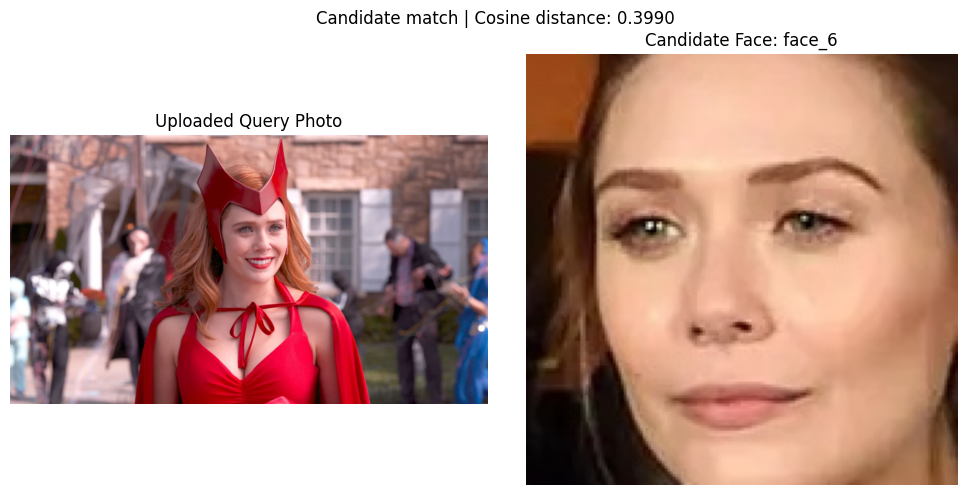

Result: Candidate match — verify before accepting.

Top candidates (lower distance is better):
face_6 | face_6.jpg | distance: 0.3990
face_4 | face_4.jpg | distance: 0.9369
face_2 | face_2.jpg | distance: 0.9902


In [ ]:


from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Experimental threshold: validate with known matches and non-matches
DISTANCE_THRESHOLD = 0.45

# 1. Upload the query photo
uploaded = files.upload()
query_path = next(iter(uploaded))

query_img = cv2.imread(query_path)

if query_img is None:
    raise ValueError("Could not read the uploaded query image.")

# 2. Detect faces in the query photo
query_faces = app.get(query_img)

if not query_faces:
    raise ValueError("No face detected. Try a clearer photo.")

# Select the largest detected face
query_face = max(
    query_faces,
    key=lambda f: (
        (f.bbox[2] - f.bbox[0]) *
        (f.bbox[3] - f.bbox[1])
    )
)

query_embedding = query_face.normed_embedding.astype(
    np.float32
).tolist()

# 3. Search the existing ChromaDB collection
if collection.count() == 0:
    raise ValueError("ChromaDB is empty. Run the embedding-storage cell.")

results = collection.query(
    query_embeddings=[query_embedding],
    n_results=min(3, collection.count()),
    include=["metadatas", "distances"]
)

if not results["ids"][0]:
    raise ValueError("No results returned from ChromaDB.")

# 4. Get the closest candidate
best_id = results["ids"][0][0]
best_metadata = results["metadatas"][0][0]
best_distance = float(results["distances"][0][0])

print("Closest candidate:", best_id)
print(f"Cosine distance: {best_distance:.4f}")
print(f"Experimental threshold: {DISTANCE_THRESHOLD:.2f}")

# Display the uploaded query photo
query_rgb = cv2.cvtColor(query_img, cv2.COLOR_BGR2RGB)

if best_distance <= DISTANCE_THRESHOLD:
    # A candidate passed the experimental threshold
    matched_filename = best_metadata["source"]
    matched_path = os.path.join("stored-faces", matched_filename)

    matched_img = cv2.imread(matched_path)

    if matched_img is None:
        raise FileNotFoundError(
            f"Cannot find {matched_path}. "
            "Check that the stored-faces folder still exists."
        )

    matched_rgb = cv2.cvtColor(matched_img, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(query_rgb)
    axes[0].set_title("Uploaded Query Photo")
    axes[0].axis("off")

    axes[1].imshow(matched_rgb)
    axes[1].set_title(f"Candidate Face: {best_id}")
    axes[1].axis("off")

    plt.suptitle(
        f"Candidate match | Cosine distance: {best_distance:.4f}"
    )
    plt.tight_layout()
    plt.show()

    print("Result: Candidate match — verify before accepting.")

else:
    # Reject the candidate instead of presenting it as a match
    plt.figure(figsize=(5, 5))
    plt.imshow(query_rgb)
    plt.title("Uploaded Photo — No Confident Match")
    plt.axis("off")
    plt.show()

    print("Result: No confident match.")
    print("The closest candidate was rejected by the threshold.")

# 5. Show the top candidates for debugging
print("\nTop candidates (lower distance is better):")

for face_id, metadata, distance in zip(
    results["ids"][0],
    results["metadatas"][0],
    results["distances"][0]
):
    print(
        f"{face_id} | {metadata['source']} | "
        f"distance: {float(distance):.4f}"
    )
